In [389]:
import numpy as np

from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize

import matplotlib.pyplot as plt



Define as classes utilizadas

In [390]:
import math

class CarParams:

    def __init__(self, wheel_radius, gear_ratio, track_width, loss_coeff, T_min, T_max, Ploss_scale, mass, yaw_inertia):

        self.wheel_radius = wheel_radius
        self.gear_ratio = gear_ratio
        self.track_width = track_width
        self.loss_coeff = loss_coeff
        self.T_min = T_min
        self.T_max = T_max
        self.Ploss_scale = Ploss_scale
        self.mass = mass
        self.yaw_inertia = yaw_inertia
    
class Reference:

    def __init__(self, Fx: float, Mz: float):
        self.Fx = Fx    # N
        self.Mz = Mz    # N.m

class WeelTork:
    def __init__(self, Fl: float, Fr: float, Rl: float, Rr: float):

        self.Fl = Fl
        self.Fr = Fr
        self.Rl = Rl
        self.Rr = Rr

    def __str__(self):
        return F"Fl: {self.Fl:.2f} Fr: {self.Fr:.2f} Rl: {self.Rl:.2f} Rr: {self.Rr:.2f}"

    def to_array(self):
        return np.array(
            [self.Fl, self.Fr, self.Rl, self.Rr],
            dtype=float
        )

class Vehicle_state:
    """
    Representa o estado dinâmico e a posição de um veículo no plano XY.

    Parameters
    ----------
    X : float
        Posição longitudinal no sistema de coordenadas global [m].

    Y : float
        Posição lateral no sistema de coordenadas global [m].

    psi : float
        Orientação (ângulo de guinada) do veículo em relação ao eixo X global [rad].

    vx : float
        Velocidade longitudinal do veículo no sistema de coordenadas local [m/s].

    omega : float
        Velocidade angular de guinada do veículo [rad/s].
    """

    def __init__(self, X, Y, psi, vx, omega):

        self.X = X
        self.Y = Y
        self.psi = psi
        self.vx = vx
        self.omega = omega


    def _get_angle_arrow(self, angle_rad: float) -> str:
        arrows = ["→", "↘", "↓", "↙", "←", "↖", "↑", "↗"]

        # Normaliza o ângulo para [0, 2π)
        angle_rad %= 2 * math.pi

        # Cada direção ocupa π/4 radianos
        index = round(angle_rad / (math.pi / 4)) % 8

        return arrows[index]
    
    def __str__(self):
        return f"P: ({self.X:.2f}m, {self.Y:.2f}m) V: {self.vx:.2f}m/s {self._get_angle_arrow(self.psi)} w: {self.omega}rad"

Define a função que da a dinamica do veiculo

In [391]:
def vehicle_dynamics(T: WeelTork, state: Vehicle_state, params: CarParams, dt) -> Vehicle_state:

    # Estado atual
    X = state.X
    Y = state.Y 
    psi = state.psi 
    vx = state.vx 
    omega = state.omega

    # Forças e momento gerados pelos motores
    Fx, Mz, Ploss = model(T, params)

    # Parâmetros dinâmicos
    m = params.mass
    Iz = params.yaw_inertia

    # Acelerações
    ax = Fx / m
    alpha = Mz / Iz

    # Integração de Euler semi-implícita
    vx_next = vx + ax * dt
    omega_next = omega + alpha * dt

    psi_next = psi + omega_next * dt

    X_next = X + vx_next * np.cos(psi_next) * dt
    Y_next = Y + vx_next * np.sin(psi_next) * dt

    return Vehicle_state(
        X_next,
        Y_next,
        psi_next,
        vx_next,
        omega_next
    )

Plota o caminho

In [392]:
def plot_trajectory(
    states: list[Vehicle_state],
    grid: list[list[int]],
    path: list[tuple[int, int]],
    CELL_WIDTH: float = 0.1,
) -> None:

    if not states:
        raise ValueError("A lista de estados está vazia.")

    if not grid or not grid[0]:
        raise ValueError("O grid está vazio.")

    if not path:
        raise ValueError("O caminho está vazio.")

    # Extrair posições do veículo
    X = np.array([state.X for state in states])
    Y = np.array([state.Y for state in states])
    psi = np.array([state.psi for state in states])

    grid = np.array(grid)

    rows, cols = grid.shape

    # Coordenadas dos centros das células
    path_X = np.array([
        (j + 0.5) * CELL_WIDTH for i, j in path
    ])

    path_Y = np.array([
        (i + 0.5) * CELL_WIDTH for i, j in path
    ])

    fig, ax = plt.subplots(figsize=(10, 8))

    # Plotar grid
    ax.imshow(
        grid,
        cmap='RdYlGn',
        origin='upper',
        extent=[
            0,
            cols * CELL_WIDTH,
            rows * CELL_WIDTH,
            0
        ],
        interpolation='nearest',
        alpha=0.35,
        vmin=0,
        vmax=10
    )

    # Linhas do grid
    ax.set_xticks(np.arange(0, cols * CELL_WIDTH + CELL_WIDTH, CELL_WIDTH))
    ax.set_yticks(np.arange(0, rows * CELL_WIDTH + CELL_WIDTH, CELL_WIDTH))

    ax.grid(True, color='black', linewidth=0.5, alpha=0.4)

    # Caminho do Dijkstra
    ax.plot(
        path_X,
        path_Y,
        color='orange',
        linewidth=2,
        linestyle='--',
        marker='.',
        markersize=5,
        label='Caminho Dijkstra',
        zorder=3
    )

    # Trajetória real do veículo
    ax.plot(
        X, Y,
        color='blue',
        linewidth=2,
        label='Trajetória do veículo',
        zorder=4
    )

    # Posição inicial
    ax.scatter(
        X[0], Y[0],
        color='lime',
        edgecolors='black',
        s=100,
        marker='o',
        label='Início',
        zorder=5
    )

    # Posição final
    ax.scatter(
        X[-1], Y[-1],
        color='red',
        edgecolors='black',
        s=100,
        marker='X',
        label='Final',
        zorder=5
    )

    # Orientação inicial e final
    arrow_length = CELL_WIDTH * 0.5

    for idx, label in [(0, 'Inicial'), (-1, 'Final')]:
        ax.quiver(
            X[idx], Y[idx],
            np.cos(psi[idx]),
            np.sin(psi[idx]),
            angles='xy',
            scale_units='xy',
            scale=1 / arrow_length,
            color='black',
            width=0.005,
            zorder=6
        )

    # Limites do mapa
    ax.set_xlim(0, cols * CELL_WIDTH)
    ax.set_ylim(rows * CELL_WIDTH, 0)

    ax.set_aspect('equal')

    ax.set_xlabel('X [m]')
    ax.set_ylabel('Y [m]')
    ax.set_title('Trajetória do veículo e caminho Dijkstra')

    ax.legend(loc='upper right')

    plt.tight_layout()
    plt.show()


Define a funcao que implementa o modelo

In [393]:
def model(T: WeelTork, params: CarParams):
    """
    Modelo simplificado de distribuição de torque para veículo
    com quatro motores nas rodas.

    Parameters
    ----------
    T : WeelTork
        Torques [T_fl, T_fr, T_rl, T_rr] em N.m.

    params : CarParams
        Parâmetros do veículo.

    Returns
    -------
    Fx : float
        Força longitudinal [N].

    Mz : float
        Momento de guinada [N.m].

    Ploss : float
        Perdas totais dos motores [W].
    """

    r = params.wheel_radius
    i0 = params.gear_ratio
    d = params.track_width

    # Força longitudinal total
    Fx = (i0 / r) * (T.Fl + T.Fr + T.Rl + T.Rr)

    # Momento de guinada
    Mz = (d * i0 / (2 * r)) * (
        T.Fl - T.Fr + T.Rl - T.Rr
    )

    # Modelo simplificado de perdas dos motores
    # Ploss = k_loss * T^2
    k_loss = params.loss_coeff

    Ploss = k_loss * np.sum(np.asarray([T.Fl, T.Fr, T.Rl, T.Rr]) ** 2)

    return Fx, Mz, Ploss

Define a classe base do solver

In [394]:
# n_var: Número de variáveis de decisão

# n_obj: Número de funções objetivo

# n_ieq_constr: Número de restrições de desigualdade

# n_eq_constr: Número de restrições de igualdade

# xl: Limites inferiores das variáveis

# xu: Limites superiores das variáveis

# X: Valores das variáveis de decisão recebidos pelo modelo


# out: Dicionário utilizado para armazenar os resultados

# out["F"]: valores das funções objetivo.

# out["G"]: valores das restrições de desigualdade.

# out["H"]: valores das restrições de igualdade.


class TorqueDistributionProblem(ElementwiseProblem):

    def __init__(
        self,
        params: CarParams,
        ref: Reference,
        T_prev: WeelTork,
        weights=None
    ):

        self.params = params

        self.Fx_ref = ref.Fx
        self.Mz_ref = ref.Mz

        self.T_prev = np.asarray([T_prev.Fl, T_prev.Fr, T_prev.Rl, T_prev.Rr], dtype=float)

        if weights is None:
            weights = {
                "force": 1.0,
                "yaw": 1.0,
                "energy": 0.1,
                "torque_change": 0.01
            }

        self.weights = weights

        # Limites de torque por motor
        T_min = params.T_min
        T_max = params.T_max

        # Escalas para normalização
        self.Fx_scale = max(abs(self.Fx_ref), 100.0)
        self.Mz_scale = max(abs(self.Mz_ref), 100.0)
        self.Ploss_scale = params.Ploss_scale
        self.T_scale = max(abs(T_max), abs(T_min), 1.0)

        super().__init__(
            n_var=4,
            n_obj=2,
            n_ieq_constr=1,
            xl=np.full(4, T_min),
            xu=np.full(4, T_max)
        )

    def _evaluate(self, x, out, *args, **kwargs):

        T = WeelTork(
            Fl=x[0],
            Fr=x[1],
            Rl=x[2],
            Rr=x[3],
        )

        Fx, Mz, Ploss = model(T, self.params)

        # Objetivos originais
        # f1 = (Fx - self.Fx_ref)**2
        f1 = (Mz - self.Mz_ref)**2
        f2 = Ploss

        # Normalização
        f1_norm = f1
        f2_norm = f2

        out["F"] = np.column_stack([
            # f1_norm,
            f1_norm,
            f2_norm
        ])

        # Restrição de força longitudinal
        epsilon = 100  # Tolerância em N

        g1 = self.Fx_ref - Fx - epsilon

        out["G"] = g1.reshape(-1, 1)


A função abaixo plota a curva de pareto dada a solução

In [395]:
def plot_pareto(F):
    plt.figure(figsize=(9, 6))

    plt.scatter(
        F[:, 0],
        F[:, 1],
        c='blue',
        s=35,
        alpha=0.8
    )

    plt.xlabel('Erro de momento de guinada normalizado')
    plt.ylabel('Perdas energéticas normalizadas')

    plt.title('Fronteira de Pareto - NSGA-II')

    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

## Exemplo de utilizacao

In [396]:
# Definindo algoritmo e quantidade de individuos da população

algorithm = NSGA2(
    pop_size=100,
    eliminate_duplicates=True
)

# Definindo parametros do veículo
car_params = CarParams(
    wheel_radius=0.10,      # m
    gear_ratio=1.0,         # -
    track_width=0.40,       # m

    T_min=0.0,              # N.m
    T_max=5.0,              # N.m

    loss_coeff=0.5,
    Ploss_scale=1000.0,     # W

    mass=12.0,              # kg
    yaw_inertia=0.80        # kg.m²
)


Cria um ambiente com custos variaveis para construir o caminho

In [397]:
import heapq
import math

def dijkstra(grid, inicio, destino):
    linhas = len(grid)
    colunas = len(grid[0])

    # Movimentos: cima, baixo, esquerda, direita e diagonais
    movimentos = [
        (-1,  0, 1.0),
        ( 1,  0, 1.0),
        ( 0, -1, 1.0),
        ( 0,  1, 1.0),
        (-1, -1, math.sqrt(2)),
        (-1,  1, math.sqrt(2)),
        ( 1, -1, math.sqrt(2)),
        ( 1,  1, math.sqrt(2))
    ]

    distancias = {inicio: 0}
    anteriores = {}
    fila = [(0, inicio)]

    while fila:
        custo_atual, atual = heapq.heappop(fila)

        if atual == destino:
            break

        if custo_atual > distancias.get(atual, float('inf')):
            continue

        i, j = atual

        for di, dj, distancia in movimentos:
            ni, nj = i + di, j + dj

            # Verifica limites do grid
            if not (0 <= ni < linhas and 0 <= nj < colunas):
                continue

            # Ignora obstáculos
            if grid[ni][nj] == 0:
                continue

            vizinho = (ni, nj)

            # Custo para entrar na célula
            novo_custo = (
                custo_atual +
                grid[ni][nj] * distancia
            )

            if novo_custo < distancias.get(vizinho, float('inf')):
                distancias[vizinho] = novo_custo
                anteriores[vizinho] = atual

                heapq.heappush(
                    fila,
                    (novo_custo, vizinho)
                )

    # Verifica se existe caminho
    if destino not in distancias:
        return []

    # Reconstrói o caminho
    caminho = []
    atual = destino

    while atual != inicio:
        caminho.append(atual)
        atual = anteriores[atual]

    caminho.append(inicio)

    return caminho[::-1]

In [ ]:
def force_moment_to_torque(Fx, Mz, params: CarParams) -> WeelTork:

    r = params.wheel_radius
    i = params.gear_ratio
    d = params.track_width

    # Soma dos torques das rodas
    T_sum = Fx * r / i

    # Diferença entre os torques esquerdo e direito
    T_diff = 2 * r * Mz / (d * i)

    # Torque total de cada lado
    T_left = (T_sum + T_diff) / 2
    T_right = (T_sum - T_diff) / 2

    # Distribuição entre os eixos dianteiro e traseiro
    T_fl = T_left / 2
    T_rl = T_left / 2

    T_fr = T_right / 2
    T_rr = T_right / 2

    # Saturação dos motores
    T_min = params.T_min
    T_max = params.T_max

    return WeelTork(
        Fl=np.clip(T_fl, T_min, T_max),
        Fr=np.clip(T_fr, T_min, T_max),
        Rl=np.clip(T_rl, T_min, T_max),
        Rr=np.clip(T_rr, T_min, T_max)
    )

def generate_torque_reference(
    caminho,
    estado_inicial: Vehicle_state,
    params: CarParams,
    cell_width: float,
    dt: float = 0.01,
    v_ref: float = 0.3,
    Kp_psi: float = 1.0,
    Kd_psi: float = 2.0,
    Kp_v: float = 20.0
):

    torques_referencia = []
    estados_calculados = []

    # Converter caminho (linha, coluna) em coordenadas (X, Y)
    waypoints = np.array([
        (
            (col + 0.5) * cell_width,
            (row + 0.5) * cell_width
        )
        for row, col in caminho
    ])

    state = estado_inicial

    waypoint_idx = 1

    # Simulação ao longo do caminho
    for k in range(10000):

        estados_calculados.append(state)

        # Verificar chegada ao destino
        distancia_final = np.linalg.norm(
            np.array([state.X, state.Y]) - waypoints[-1]
        )

        if distancia_final < 0.03:
            break

        # Selecionar próximo waypoint
        while waypoint_idx < len(waypoints) - 1:

            target = waypoints[waypoint_idx]

            distancia = np.linalg.norm(
                target - np.array([state.X, state.Y])
            )

            if distancia < cell_width / 2:
            # if distancia < 0.04:
                waypoint_idx += 1
            else:
                break

        target = waypoints[waypoint_idx]

        # Orientação desejada
        psi_ref = np.arctan2(
            target[1] - state.Y,
            target[0] - state.X
        )

        # Erro angular normalizado
        e_psi = np.arctan2(
            np.sin(psi_ref - state.psi),
            np.cos(psi_ref - state.psi)
        )

        # Controle de orientação
        Mz_ref = Kp_psi * e_psi - Kd_psi * state.omega

        # Controle de velocidade
        Fx_ref = Kp_v * (v_ref - state.vx)

        # Limites de força e momento
        Fx_ref = np.clip(Fx_ref, 0.0, 30.0)
        Mz_ref = np.clip(Mz_ref, -2.0, 2.0)

        # Converter referências em torques
        T_ref = force_moment_to_torque(
            Fx_ref,
            Mz_ref,
            params
        )

        torques_referencia.append(T_ref)

        # Atualizar estado do veículo
        next_state = vehicle_dynamics(
            T_ref,
            state,
            params,
            dt
        )

        # Compatibilidade com retorno em array NumPy
        if isinstance(next_state, np.ndarray):
            state = Vehicle_state(*next_state)
        else:
            state = next_state

    return torques_referencia, estados_calculados

Loop principal onde é feita é calculado o caminho e aplicado os torques iterativamente

Número de amostras: 10000


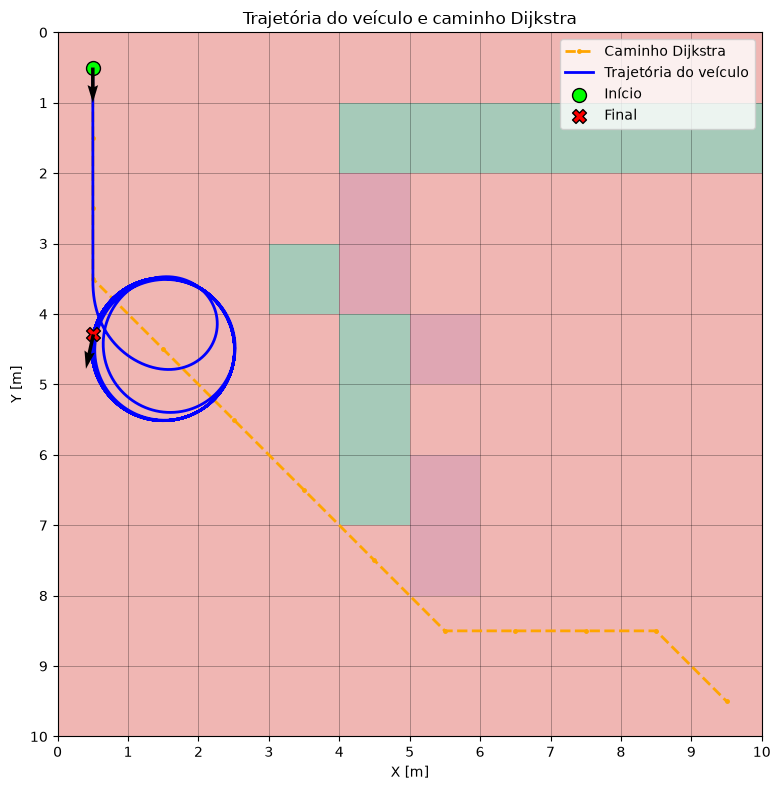

In [399]:
CELL_WIDTH = 1 # 10 cm

grid = [
    [1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
    [1, 1, 1, 1, 10, 10, 10, 10, 10, 10],
    [1, 1, 1, 1, 0, 1, 1, 1, 1, 1],
    [1, 1, 1, 10, 0, 1, 1, 1, 1, 1],
    [1, 1, 1, 1, 10, 0, 1, 1, 1, 1],
    [1, 1, 1, 1, 10, 1, 1, 1, 1, 1],
    [1, 1, 1, 1, 10, 0, 1, 1, 1, 1],
    [1, 1, 1, 1, 1, 0, 1, 1, 1, 1],
    [1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
    [1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
]

inicio = (0, 0)
destino = (9, 9)

caminho = dijkstra(grid, inicio, destino)


estado_atual = Vehicle_state(
    X=CELL_WIDTH / 2,
    Y=CELL_WIDTH / 2,
    psi=(math.pi / 2),
    vx=0,
    omega=0.0
)

dt = 0.01

torques_referencia, estados_calculados = generate_torque_reference(
    caminho=caminho,
    estado_inicial=estado_atual,
    params=car_params,
    cell_width=CELL_WIDTH,
    dt=dt,
    v_ref=0.3
)

print("Número de amostras:", len(torques_referencia))

plot_trajectory(
    estados_calculados,
    grid,
    caminho,
    CELL_WIDTH
)

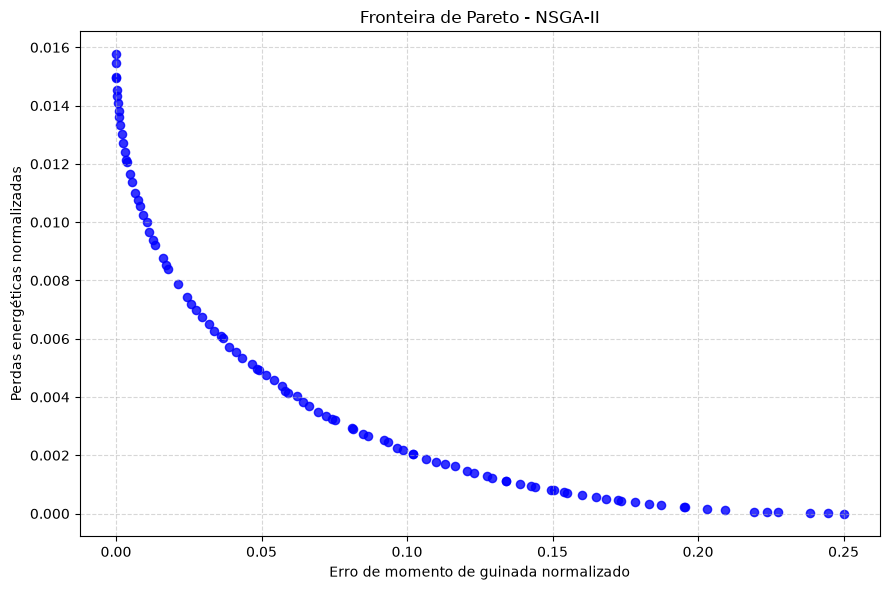

Torques ótimos [N.m]: Fl: 0.11 Fr: 0.00 Rl: 0.14 Rr: 0.00
Fx [N]: 2.5008007387316065
Mz [N.m]: 0.4999701428160228
Perdas [W]: 0.015761387516690692
xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx


In [400]:
# Torques aplicados no passo anterior
T_prev = WeelTork(
    Fl=0,
    Fr=0,
    Rl=0,
    Rr=0,
)

# Referências do controlador
ref = Reference(
    Fx=20.0,
    Mz=0.5
)

problem = TorqueDistributionProblem(
    params=car_params,
    ref=ref,
    T_prev=T_prev
)

result = minimize(
    problem,
    algorithm,
    termination=("n_gen", 100),
    seed=1,
    verbose=False
)


# Escolhe uma das soluções pareto otimo para plotar
T_result = result.X[0]
pareto_F = result.F
plot_pareto(pareto_F)

T_opt = WeelTork(
    Fl=T_result[0],
    Fr=T_result[1],
    Rl=T_result[2],
    Rr=T_result[3],
)

Fx_opt, Mz_opt, Ploss_opt = model(T_opt, car_params)

print("Torques ótimos [N.m]:", T_opt)
print("Fx [N]:", Fx_opt)
print("Mz [N.m]:", Mz_opt)
print("Perdas [W]:", Ploss_opt)

print("x" * 64)
